# 03 · 대표 ETF 4종의 CUSUM 검정창 선정 연구

**연구 질문.** T12 연간 사후 분산 검정을 그대로 두고, 이동 검정창 길이 `w`(거래일)를 무엇으로 정해야 하는가? 구조변화가 없을 때는 연중 경보가 드물고, 알려진 분산 변화가 있을 때는 60거래일 안에 경보가 나야 한다. 이 두 조건을 함께 만족하는 창이 있는지를, 결과를 보기 전에 고정한 규칙(W1)으로 판정한다.

**왜 필요한가.** T12 는 이동창 `w ∈ {20, 30, 60, 120, 252}` 의 점별 95% 임계값으로 경보를 셌다. 점별 5% 는 연간 5% 가 아니다. T12 감사에서 귀무일 때 연중 1회 이상 경보가 날 확률은 약 0.68 이었다. 따라서 창 길이를 비교하려면 먼저 **연간 단위로 보정한 임계값**과, 정답을 아는 **합성 대립**에서의 검출률이 필요하다. ETF 가격이 크게 움직였다는 사실은 분산 구조변화의 정답이 아니므로, 실제 ETF 는 판정 뒤의 사례로만 읽는다.

**용어.**
- CUSUM: 누적합.
- SVR: 서포트 벡터 회귀. T12 가 분산 예측에 쓴 모형이다.
- GARCH: 일반화 자기회귀 조건부 이분산. 변동성 군집을 만드는 시계열 모형이다.
- OOS: 표본 외. 적합에 쓰지 않은 기간을 뜻한다.
- PURE: 창 전체가 검정연도 안에 있는 날이다.

**입력.**
- 출발점은 T12 커밋 `39566e2b0b490623e55adccb0f6a4dbddf5c54de` 의 00·01·02 실행 결과다. 동결 run 은 `b_nb_20261016T181251` 이다.
- 사전 계약 `research/03_04_연구계약.md` 와 설정 `configs/t13_window_study_v1.json` 만 사용한다. 둘 다 결과를 보기 전에 고정했다.
- 기존 노트북·코드·원자료는 수정하지 않는다. 후속 04 는 이 노트북의 임계값과 판정을 그대로 가져간다.

**기간.** 핵심은 2021–2025 다. 2020 은 학습 이력이 1년뿐인 파일럿이고, 2026 은 10/2 까지의 부분·비블라인드 구간이다.

**네 종목.**

| 코드 | 이름 | 비고 |
|---|---|---|
| 069500 | KODEX 200 | |
| 229200 | KODEX 코스닥150 | |
| 148070 | KIWOOM 국고채10년 | |
| 102110 | TIGER 200 | 팀 확정 근거가 없는 **잠정 비교군** |

102110 은 069500 과 같은 KOSPI200 노출이다. 그래서 네 종목을 독립된 네 노출로 세지 않는다.

**실행.**
1. `python scripts/t13_build_notebooks.py --write`
2. `python scripts/run_t13_notebooks.py`

R2H `.venv` 를 써야 한다. 합성 모의 전체와 SVR 재적합을 포함해 약 3분이 걸린다. 인터넷 접속이나 데이터 다운로드는 하지 않는다.

## 1. 통계적 정의 — 무엇을 측정하고 무엇을 측정하지 않는가

**잔차.** T12 가 연초 이전 자료로 SVR–GARCH 분산을 적합해 만든 표준화 잔차는 `e_t = r_t / √v̂_t` 이다. `r_t` 는 100·Δlog 종가(%) 다. 정책마다 `v̂_t` 를 만드는 방식이 다르다.

| 정책 | `v̂_t` |
|---|---|
| A | 관측 분산 proxy 의 지연값을 입력으로 쓴다 |
| B | 예측분산의 재귀 지연값을 쓴다 |
| base | 과거 60거래일 표본분산 `σ60²` 이다. CUSUM **검정창 w=60** 과는 별개다 |

proxy 길이 `m=5`, 부트스트랩 블록 `L=10`, 아직 정하지 않은 CNN 입력 길이도 모두 `w` 가 아니다.

**통계량.** 길이 `w` 의 창 안 유효 잔차 수를 `n` 이라 하자. 원본 `rolling_cusum` 은 다음을 계산한다.

- `S_k = Σ_{i≤k} e_i²`
- `τ̂² = n⁻¹Σe_i⁴ − (n⁻¹Σe_i²)²`
- `T_t(w) = max_k |S_k − k·S_n/n| / (√n · τ̂)`

유효 수가 `⌈0.9w⌉` 미만이거나 `τ̂² ≤ 0` 이면 계산하지 않는다. `T` 는 분산 이탈의 크기이며, 상승 방향이나 가격 급등을 나타내는 점수가 아니다. `k̂` 는 창 안 최대 이탈 위치의 **사후 추정**이므로, 실제 첫 경보일 `alarm_at` 과 구별한다.

**평가일.**
- PURE 는 연도 안에서 w일을 온전히 채운 `t ≥ w−1` 이다.
- 창 사이 공정 비교의 주 분모는 네 창이 모두 유한한 `t ≥ 119` 날짜의 교집합이다. 합성 245일 연도에서는 126일이다.
- `w=252` 는 실제 연도의 거래일(242–248)보다 길다. 그래서 PURE 비교가 **구조적으로 불가**하다. 이것은 '경보 0' 이 아니다.

**귀무 H0.** 분산 구조변화가 없는 *알려진 생성모형* 세 가지다: 정규 독립, 단위분산 t5 독립, GARCH 군집.
- 각 `w` 에서 귀무마다 보정 경로 500회의 `max_t T_t(w)` 95% 분위를 구하고, 세 값 중 최대를 연간 임계값 `c_w` 로 정한다.
- 이 값은 T12 의 점별 iid 95% 나 원문 표기 1.3397 과 다른, **연중 날짜 최대값 보정**이다.
- 보정과 평가는 서로 독립인 난수열에서 뽑는다. 귀무마다 500회로 보정하고 1,000회로 평가한다.

**대립 H1.** GARCH 검정연도의 123번째 날(`k=122`)부터 분산을 바꾼다.
- 지속 ×2 상승
- 지속 ×0.5 하락
- 40일 동안만 ×2
- 연말까지 1→2배로 점진 증가

**검출과 지연.**
- 변화 후 60거래일 안에 첫 경보가 나면 **검출**이다. 그 거래일 차가 **지연**이다.
- 미검출은 60일 초과로 검열한다. 지연은 검출된 반복에 **조건부**이므로 검출률과 함께 읽는다.
- 여러 `w`·정책·ETF 를 한꺼번에 5% 로 통제한다고 주장하지 않는다.

In [1]:
# 새 커널 첫 셀: BLAS 스레드를 NumPy 로드 전에 1로 고정해 결과를 결정적으로 만든다.
import os  # 환경변수 설정
import sys  # 인터프리터·모듈 경로 확인
from pathlib import Path  # 저장소 상대 경로

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):  # 네 BLAS 계열 변수
    os.environ[key] = "1"  # 다중 스레드 합산 순서에 따른 비트 차이를 막는다
assert "numpy" not in sys.modules, "새 커널에서 첫 셀부터 실행해야 합니다"  # 숨은 커널 상태 금지
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/t13_window_study_v1.json").is_file())  # 저장소 루트 탐색
sys.path.insert(0, str(ROOT / "src"))  # 이 작업트리의 r2h 패키지를 우선 사용

import hashlib  # 파일 SHA256 지문
import importlib.metadata as metadata  # 설치 패키지 버전 조회
import json  # 03→04 인계 파일
import platform  # Python 버전
import time  # 실행 시간 기록

import matplotlib.pyplot as plt  # 그림 기본 설정
import numpy as np  # 수치 배열
import pandas as pd  # 결과표
from IPython.display import Image, display  # 표·그림 출력
from matplotlib import font_manager  # 한글 글꼴 등록

# T12 재현 환경과 같은 버전이어야 한다 (user-site 의 다른 numpy/pandas 를 잡으면 여기서 멈춘다).
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scikit-learn": "1.9.1"}  # T12 종결 기준
ACTUAL_ENV = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": metadata.version("scikit-learn")}  # 실제 커널
assert ACTUAL_ENV == EXPECTED_ENV, f"실행 환경 불일치: {ACTUAL_ENV}"  # 버전 불일치는 재현 실패로 처리
assert "site-packages" in np.__file__ and ".local" not in np.__file__, np.__file__  # user-site 패키지 차단
FONT_FILE = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")  # 한글 도판용 나눔고딕
assert FONT_FILE.is_file(), "한글 도판 렌더링을 위한 나눔고딕 파일이 없습니다"  # 글꼴 없으면 중단
font_manager.fontManager.addfont(str(FONT_FILE))  # matplotlib 글꼴 목록에 등록
plt.rcParams["font.family"] = [font_manager.FontProperties(fname=str(FONT_FILE)).get_name(), "DejaVu Sans"]  # 한글 우선·기호 대체
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지

from r2h.window_study.empirical import frozen_root, verify_frozen  # T12 동결 입력 검증
from r2h.window_study.simulation import load_cfg  # W1 동결 설정

CFG = load_cfg(ROOT)  # 동결 설정 configs/t13_window_study_v1.json 읽기
SOURCE = frozen_root(ROOT)  # T12 종결 작업트리 (일별 잔차 cache 위치)
assert Path(sys.modules["r2h"].__file__).resolve().is_relative_to((ROOT / "src").resolve())  # 다른 트리의 r2h 금지
FROZEN = verify_frozen(ROOT, SOURCE, CFG)  # 00·01·02 노트북·원자료 22개·run manifest 해시 대조
CONFIG_SHA = hashlib.sha256((ROOT / "configs/t13_window_study_v1.json").read_bytes()).hexdigest()  # 설정 지문
BASE = ROOT / "research/window_study_w1"  # W1 산출물 폴더
BASE.mkdir(parents=True, exist_ok=True)  # 없으면 만든다
print("작업트리:", ROOT)  # 실행 위치 기록
print("동결 T12:", FROZEN)  # 입력 검증 결과
print("W1 설정 SHA256:", CONFIG_SHA)  # 설정 지문
print("실행 환경:", ACTUAL_ENV, "| 인터프리터:", sys.executable)  # 재현 환경 기록

작업트리: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1016/R2H_CUSUM_Window_Study
동결 T12: {'run_id': 'b_nb_20261016T181251', 'data_version': '5f20e3e0073b521a', 'notebook_count': 3, 'raw_sha_count': 22, 'daily_ticker_count': 20, 'source_root': '/home/sieg/projects-wsl/hongik_univ_26_2/SA/1016/R2H_T12_Final'}
W1 설정 SHA256: 8489eada913a3e624149f8ce05315d5be4ca1916680c1c51b5afe734a3015681
실행 환경: {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1'} | 인터프리터: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1012_Annual_SVR–GARCH-CUSUM/R2H/.venv/bin/python


## 2. 사전 선정 규칙 — 수치보다 먼저

**예산.** 주 예산은 귀무에서 연중 1회 이상 경보가 날 확률 0.10 이다. 허용 여부는 독립 평가 반복의 **Wilson 95% 상한**으로 판정한다.

**검출기 단계.** 모형 적합 없이 잔차를 직접 생성한다. 다음을 모두 만족해야 한다.
- 세 귀무 각각에서 Wilson 상한 ≤ 0.10.
- 지속 상승과 지속 하락 모두에서 60일 검출률의 Wilson **하한** ≥ 0.15, 검출 건수 ≥ 30.
- 검출 조건부 지연의 중앙값 ≤ 30, 90분위 ≤ 60.

**적합 포함 단계.** 모의마다 T12 27-grid SVR 을 다시 적합한다.
- GARCH 귀무 200회와 ×2 상승 대립 200회를 쓴다.
- **정책 A** 가 같은 예산·하한·지연 중앙값 기준을 통과해야 한다.
- 정책·w 별 임계값은 별도의 보정 200회에서 정한다. B 와 base 는 민감도 정보이며 A 를 대신해 선정되지 않는다.

**순위.** 적격 후보만 비교한다. 파레토 기준은 다음 셋이다.
- 적합 포함 A 검출률 하한 (높을수록 좋음)
- 검출기 상승·하락 하한 중 작은 값 (높을수록 좋음)
- 적합 포함 A 의 지연 중앙값 (낮을수록 좋음)

적격 후보가 하나도 없으면 **최적창 없음**이다. 그 경우 실제 ETF 에서 경보가 적은 창을 사후에 우승시키지 않는다. 예산 0.05·0.20 은 민감도이며 W1 결정을 바꾸지 않는다. `w=252` 와 CARRY 경계는 순위에 들어가지 않는다.

In [2]:
# 검출기 수준: 세 귀무로 보정한 뒤, 독립 난수열의 귀무·대립으로 평가한다 (모형 적합 없음).
from r2h.window_study.simulation import detector_experiment, pipeline_experiment, select_windows

START03 = time.time()  # 03 전체 실행 시간 시작
DET = detector_experiment(CFG, BASE / "results/03_synthetic/detector")  # 보정 1,500·평가 7,000 반복 × 4 창
print("검출기 보정/평가 행:", len(DET["detector_cal_max.csv"]), len(DET["detector_repetitions.csv"]))  # 행 수 기록
display(DET["detector_thresholds.csv"])  # w 별 연간 최대 T 임계값 c_w
display(DET["detector_summary.csv"].round(4))  # 귀무 경보 확률·대립 검출률·Wilson 구간·지연
assert len(DET["detector_repetitions.csv"]) == 28000  # (3 귀무 + 4 대립) × 1,000 × 4 창

검출기 보정/평가 행: 6000 28000


,w,critical_annual_max,calibration_rule
0,20,1.687778,max_of_three_H0_q95_annual_max_common_days
1,30,1.847603,max_of_three_H0_q95_annual_max_common_days
2,60,2.133354,max_of_three_H0_q95_annual_max_common_days
3,120,2.536285,max_of_three_H0_q95_annual_max_common_days


,stage,dgp,w,R,any_alarm,any_alarm_ci_low,any_alarm_ci_high,mean_episodes,n_not_estimable,detected_60d,detected_ci_low,detected_ci_high,n_detected,median_delay,q90_delay
0,H0,stable_garch_clustering,20,1000,0.060,0.0469,0.0765,0.065,0,NaN,NaN,NaN,NaN,NaN,NaN
1,H0,stable_garch_clustering,30,1000,0.044,0.0329,0.0586,0.047,0,NaN,NaN,NaN,NaN,NaN,NaN
2,H0,stable_garch_clustering,60,1000,0.051,0.0390,0.0664,0.055,0,NaN,NaN,NaN,NaN,NaN,NaN
3,H0,stable_garch_clustering,120,1000,0.051,0.0390,0.0664,0.057,0,NaN,NaN,NaN,NaN,NaN,NaN
4,H0,stable_heavy_tail,20,1000,0.014,0.0084,0.0234,0.014,0,NaN,NaN,NaN,NaN,NaN,NaN
5,H0,stable_heavy_tail,30,1000,0.002,0.0005,0.0073,0.002,0,NaN,NaN,NaN,NaN,NaN,NaN
6,H0,stable_heavy_tail,60,1000,0.000,0.0000,0.0038,0.000,0,NaN,NaN,NaN,NaN,NaN,NaN
7,H0,stable_heavy_tail,120,1000,0.000,0.0000,0.0038,0.000,0,NaN,NaN,NaN,NaN,NaN,NaN
8,H0,stable_low_variance_no_change,20,1000,0.018,0.0114,0.0283,0.019,0,NaN,NaN,NaN,NaN,NaN,NaN
9,H0,stable_low_variance_no_change,30,1000,0.005,0.0021,0.0117,0.005,0,NaN,NaN,NaN,NaN,NaN,NaN


### 표 1. 검출기 수준의 귀무 경보 부담과 알려진 변화의 검출

**보정 표.** 각 `w` 에서 세 귀무의 **연중 최대 T** 95% 분위 가운데 최대값을 임계값으로 쓴다.

**요약 표의 열.**
- `R`: 반복 모의 수.
- `any_alarm`: 귀무에서 연중 1회 이상 경보가 난 반복의 비율.
- `detected_60d`: 변화 후 60거래일 안에 경보가 난 반복의 비율.
- Wilson 구간: Monte Carlo 반복 사이의 불확실성이다. ETF 의 신뢰구간이 아니다.
- 경보 에피소드: 경보일 사이가 비경보 5일 이하이면 하나로 묶는다.

임계값이 세 귀무의 최대값이기 때문에, 가장 무거운 귀무인 GARCH 군집에서 크기가 정해진다. 정규·t5 귀무에서는 경보 확률이 0 에 가깝게 보수적이다.

In [3]:
# 적합 포함 수준: 모의마다 과거 490일로 T12 fit_annual(27 grid) 을 다시 적합해 A/B/base 잔차를 만든다.
PIPE = pipeline_experiment(CFG, BASE / "results/03_synthetic/pipeline")  # 보정 200 + 귀무 200 + 대립 200 반복
print("적합 포함 보정/평가 행:", len(PIPE["pipeline_cal_max.csv"]), len(PIPE["pipeline_repetitions.csv"]))  # 행 수 기록
display(PIPE["pipeline_thresholds.csv"].round(4))  # 정책·w 별 연간 최대 T 임계값
display(PIPE["pipeline_summary.csv"].round(4))  # 정책·w 별 귀무 경보 확률·대립 검출률
assert len(PIPE["pipeline_repetitions.csv"]) == 4800  # (200 + 200) × 3 정책 × 4 창

적합 포함 보정/평가 행: 2400 4800


,policy,w,critical_annual_max,calibration_rule
0,A,20,1.4570,pipeline_garch_H0_q95_annual_max_common_days
1,A,30,1.3429,pipeline_garch_H0_q95_annual_max_common_days
2,A,60,1.2494,pipeline_garch_H0_q95_annual_max_common_days
3,A,120,1.2850,pipeline_garch_H0_q95_annual_max_common_days
4,B,20,1.6464,pipeline_garch_H0_q95_annual_max_common_days
5,B,30,1.7168,pipeline_garch_H0_q95_annual_max_common_days
6,B,60,1.8860,pipeline_garch_H0_q95_annual_max_common_days
7,B,120,2.1883,pipeline_garch_H0_q95_annual_max_common_days
8,base,20,1.6700,pipeline_garch_H0_q95_annual_max_common_days
9,base,30,1.7972,pipeline_garch_H0_q95_annual_max_common_days


,stage,dgp,policy,w,R,any_alarm,any_alarm_ci_low,any_alarm_ci_high,mean_episodes,n_not_estimable,detected_60d,detected_ci_low,detected_ci_high,n_detected,median_delay,q90_delay
0,H0,pipeline_garch_H0,A,20,200,0.035,0.0171,0.0705,0.035,0,NaN,NaN,NaN,NaN,NaN,NaN
1,H0,pipeline_garch_H0,A,30,200,0.045,0.0239,0.0833,0.050,0,NaN,NaN,NaN,NaN,NaN,NaN
2,H0,pipeline_garch_H0,A,60,200,0.070,0.0422,0.1141,0.100,0,NaN,NaN,NaN,NaN,NaN,NaN
3,H0,pipeline_garch_H0,A,120,200,0.055,0.0310,0.0958,0.075,0,NaN,NaN,NaN,NaN,NaN,NaN
4,H0,pipeline_garch_H0,B,20,200,0.000,0.0000,0.0188,0.000,0,NaN,NaN,NaN,NaN,NaN,NaN
5,H0,pipeline_garch_H0,B,30,200,0.020,0.0078,0.0503,0.020,0,NaN,NaN,NaN,NaN,NaN,NaN
6,H0,pipeline_garch_H0,B,60,200,0.050,0.0274,0.0896,0.060,0,NaN,NaN,NaN,NaN,NaN,NaN
7,H0,pipeline_garch_H0,B,120,200,0.060,0.0347,0.1019,0.080,0,NaN,NaN,NaN,NaN,NaN,NaN
8,H0,pipeline_garch_H0,base,20,200,0.015,0.0051,0.0432,0.015,0,NaN,NaN,NaN,NaN,NaN,NaN
9,H0,pipeline_garch_H0,base,30,200,0.025,0.0107,0.0572,0.025,0,NaN,NaN,NaN,NaN,NaN,NaN


### 표 2. SVR 적합을 포함한 정책별 귀무·대립

**설계.** 모의마다 과거 490일로 T12 `fit_annual` 을 새로 적합하고, 그 모형으로 A/B/base 잔차를 만든다.
- 임계값: 정책별 GARCH 무변화 **보정** 200회에서 구한다.
- **평가**: 새로 뽑은 GARCH 무변화 200회와 분산 2배 변화 200회를 쓴다.

**읽는 법.** 이 결과는 한 가지 GARCH 생성 경로에서만 확인한 것이다. 다른 군집 강도, 두꺼운 꼬리, 실제 ETF 의 참 검출률은 보장하지 않는다. 반복이 200회이므로 비율 0.05 의 Wilson 95% 구간 폭이 약 ±0.03 이다. 0.10 근처의 작은 차이는 구별하지 못한다.

In [4]:
# 실제 ETF 경보를 보지 않고, 계약의 적격성·파레토 규칙만 합성 요약표에 적용한다.
SELECTION = select_windows(CFG, DET["detector_summary.csv"], PIPE["pipeline_summary.csv"])  # w 별 4개 조건과 판정
SELECTION.to_csv(BASE / "최적창_판정과_보류사유.csv", index=False)  # 04 와 감사에 넘길 판정표
display(SELECTION)  # 조건별 통과 여부·실패 사유·판정
print("적격 후보 수:", int(SELECTION.eligible.sum()), "/", len(SELECTION))  # 적격 창 개수
print("W1 조건부 최적 후보:", SELECTION.loc[SELECTION.pareto, "w"].tolist())  # 파레토 후보 (없으면 빈 목록)

,w,detector_size_ok,detector_power_delay_ok,pipeline_A_size_ok,pipeline_A_power_delay_ok,eligible,insufficient_precision,failure_reason,pipeline_A_power_lower,detector_min_power_lower,pipeline_A_median_delay,pareto,decision
0,20,True,False,True,False,False,False,검출기 검출/지연; 적합 포함 검출/지연,0.010725,0.021094,24.0,False,비적격
1,30,True,False,True,False,False,False,검출기 검출/지연; 적합 포함 검출/지연,0.034652,0.020266,26.5,False,비적격
2,60,True,False,False,False,False,False,검출기 검출/지연; 적합 포함 귀무 상한; 적합 포함 검출/지연,0.042152,0.049550,16.5,False,비적격
3,120,True,False,True,False,False,False,검출기 검출/지연; 적합 포함 검출/지연,0.057687,0.043375,31.5,False,비적격


적격 후보 수: 0 / 4
W1 조건부 최적 후보: []


In [5]:
# 판정을 숫자로 풀어 쓴다: 귀무 크기와 검출력 중 어느 조건이 적격을 막았는가.
det = DET["detector_summary.csv"]  # 검출기 요약
pipe = PIPE["pipeline_summary.csv"]  # 적합 포함 요약
need = det.query("stage == 'H1' and dgp in ['garch_up_x2', 'garch_down_x0.5']")  # 필수 대립 두 개
print("검출기 귀무 연간 경보 Wilson 상한 최대:", round(det.query("stage == 'H0'").any_alarm_ci_high.max(), 4), "(예산 0.10)")  # 크기 조건
print("검출기 필수 대립 60일 검출률 범위:", round(need.detected_60d.min(), 3), "–", round(need.detected_60d.max(), 3))  # 점추정
print("검출기 필수 대립 Wilson 하한 최대:", round(need.detected_ci_low.max(), 4), "(기준 0.15)")  # 검출력 조건
pa = pipe.query("policy == 'A'")  # 적합 포함 정책 A
print("적합 포함 A 귀무 Wilson 상한:", dict(zip(pa.query("stage == 'H0'").w, pa.query("stage == 'H0'").any_alarm_ci_high.round(4), strict=True)))  # w 별 상한
print("적합 포함 A 대립 검출률 하한:", dict(zip(pa.query("stage == 'H1'").w, pa.query("stage == 'H1'").detected_ci_low.round(4), strict=True)))  # w 별 하한

검출기 귀무 연간 경보 Wilson 상한 최대: 0.0765 (예산 0.10)
검출기 필수 대립 60일 검출률 범위: 0.029 – 0.096
검출기 필수 대립 Wilson 하한 최대: 0.0793 (기준 0.15)
적합 포함 A 귀무 Wilson 상한: {20: 0.0705, 30: 0.0833, 60: 0.1141, 120: 0.0958}
적합 포함 A 대립 검출률 하한: {20: 0.0107, 30: 0.0347, 60: 0.0422, 120: 0.0577}


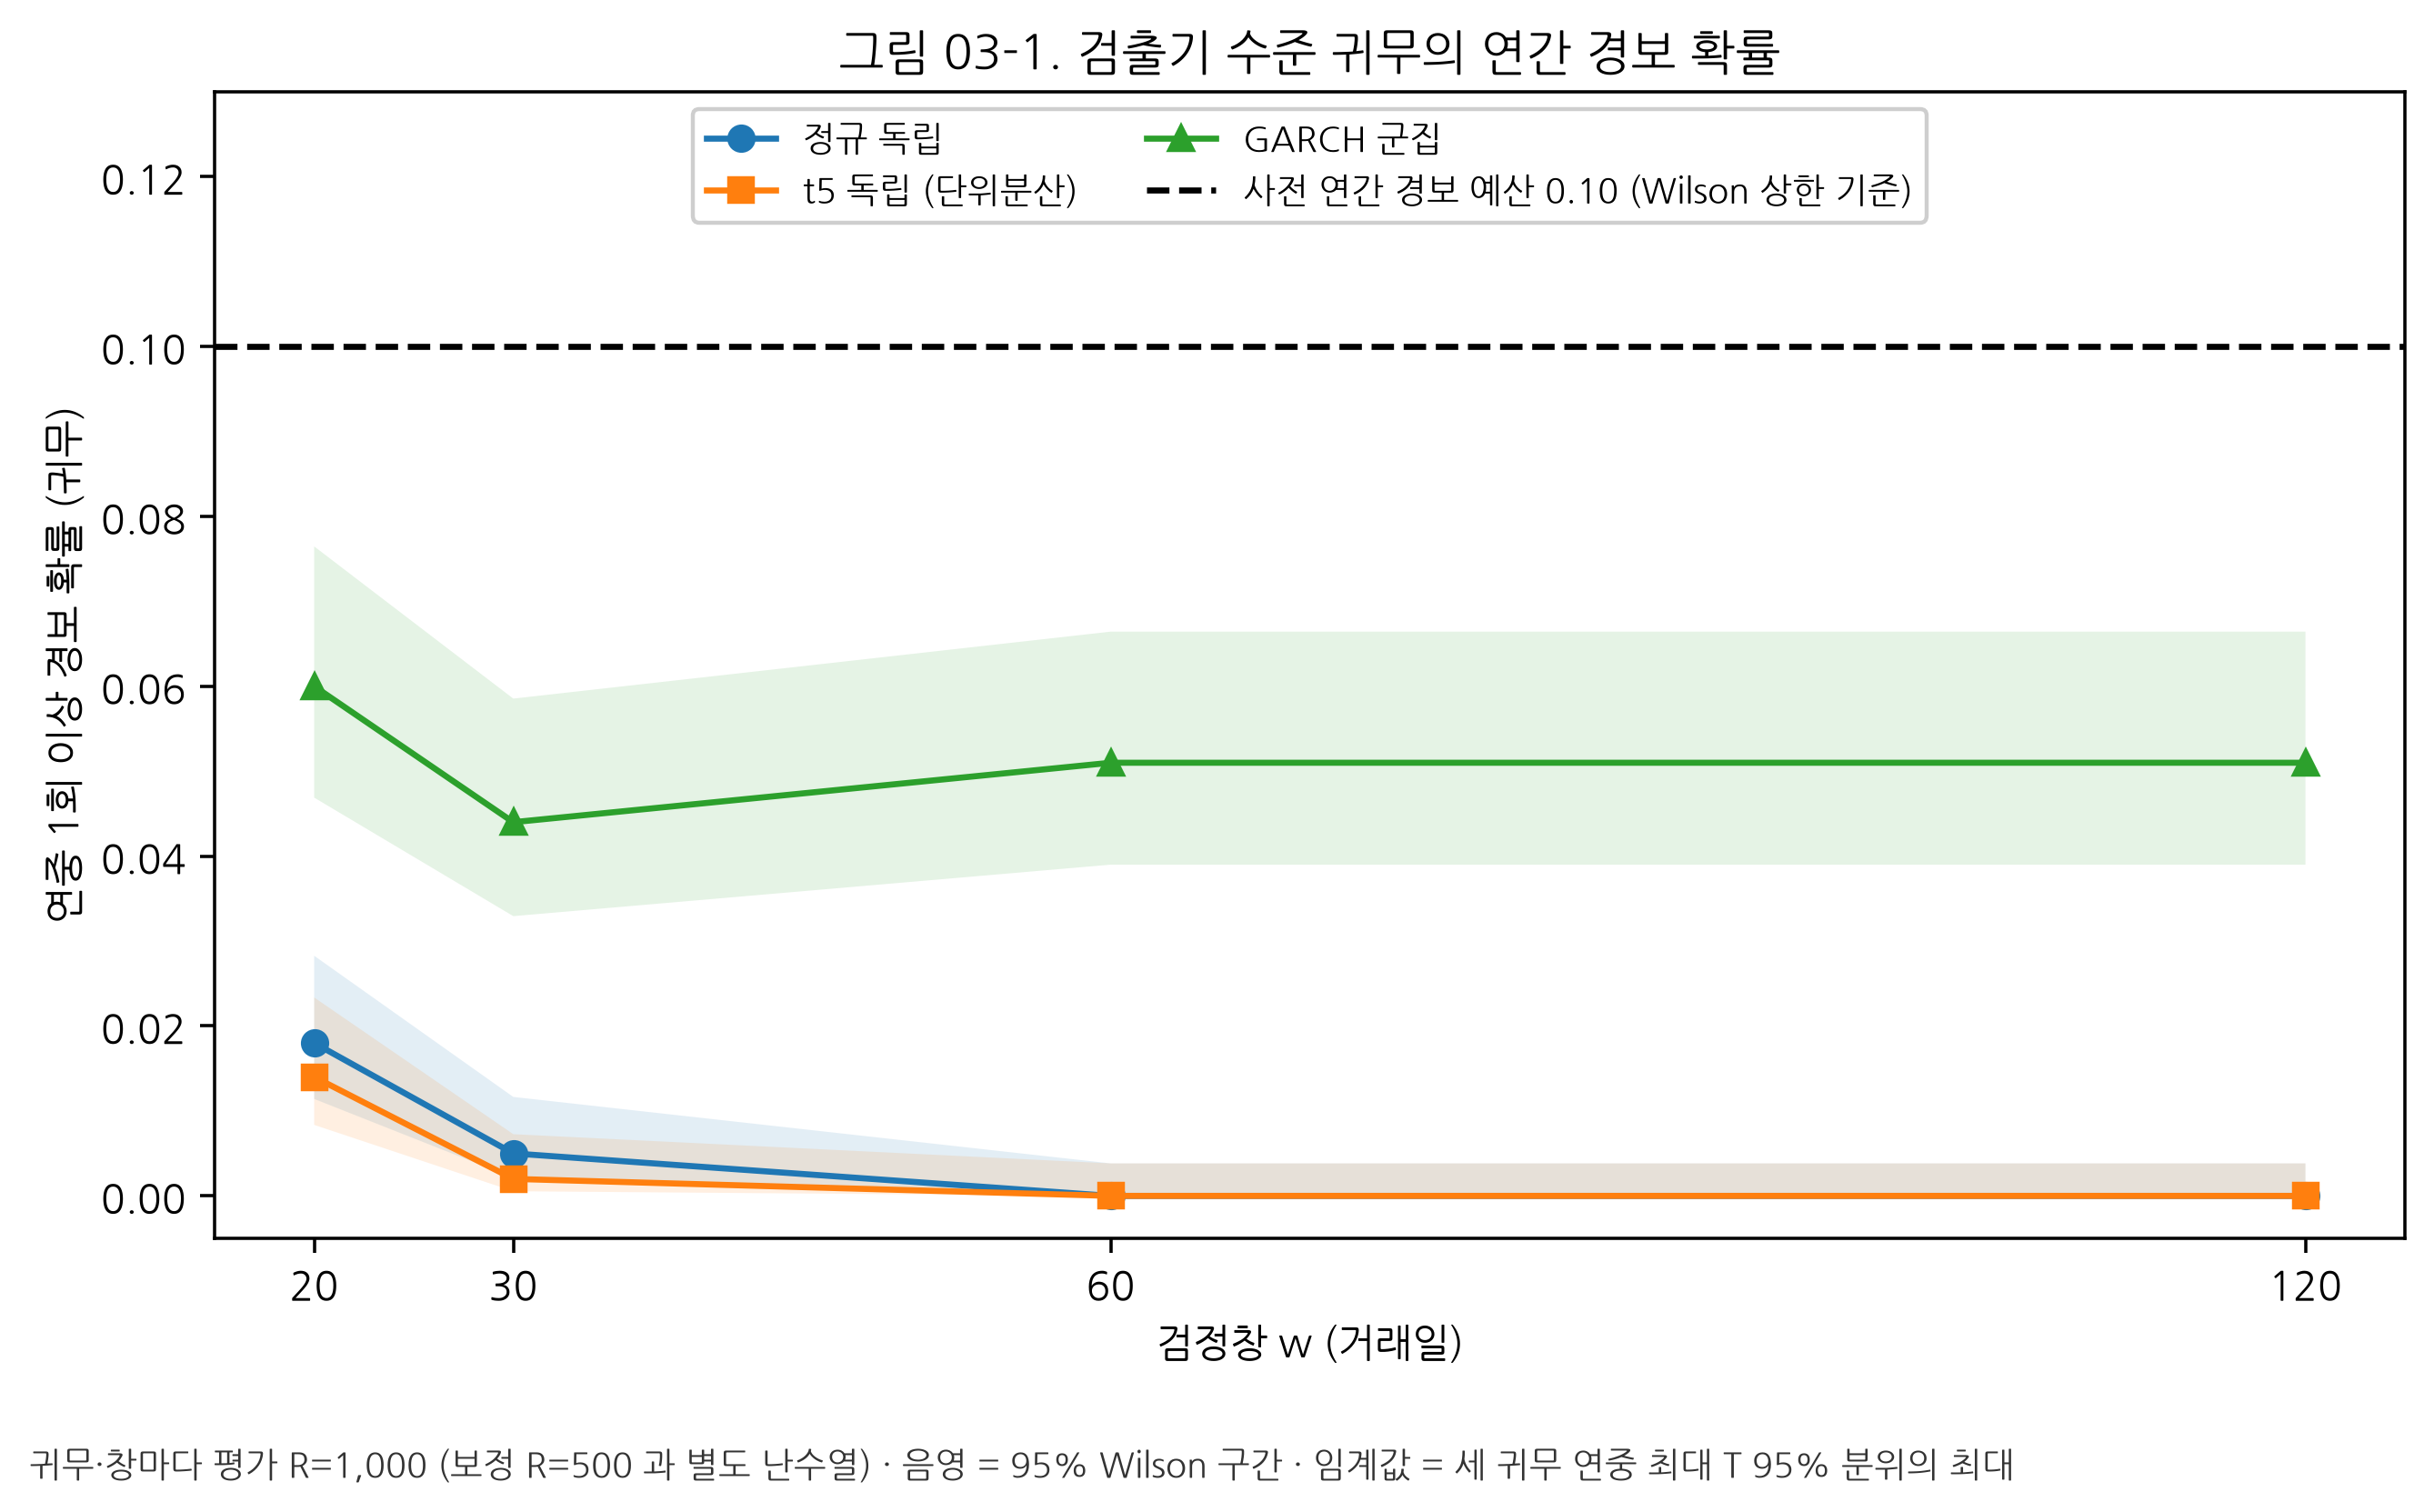

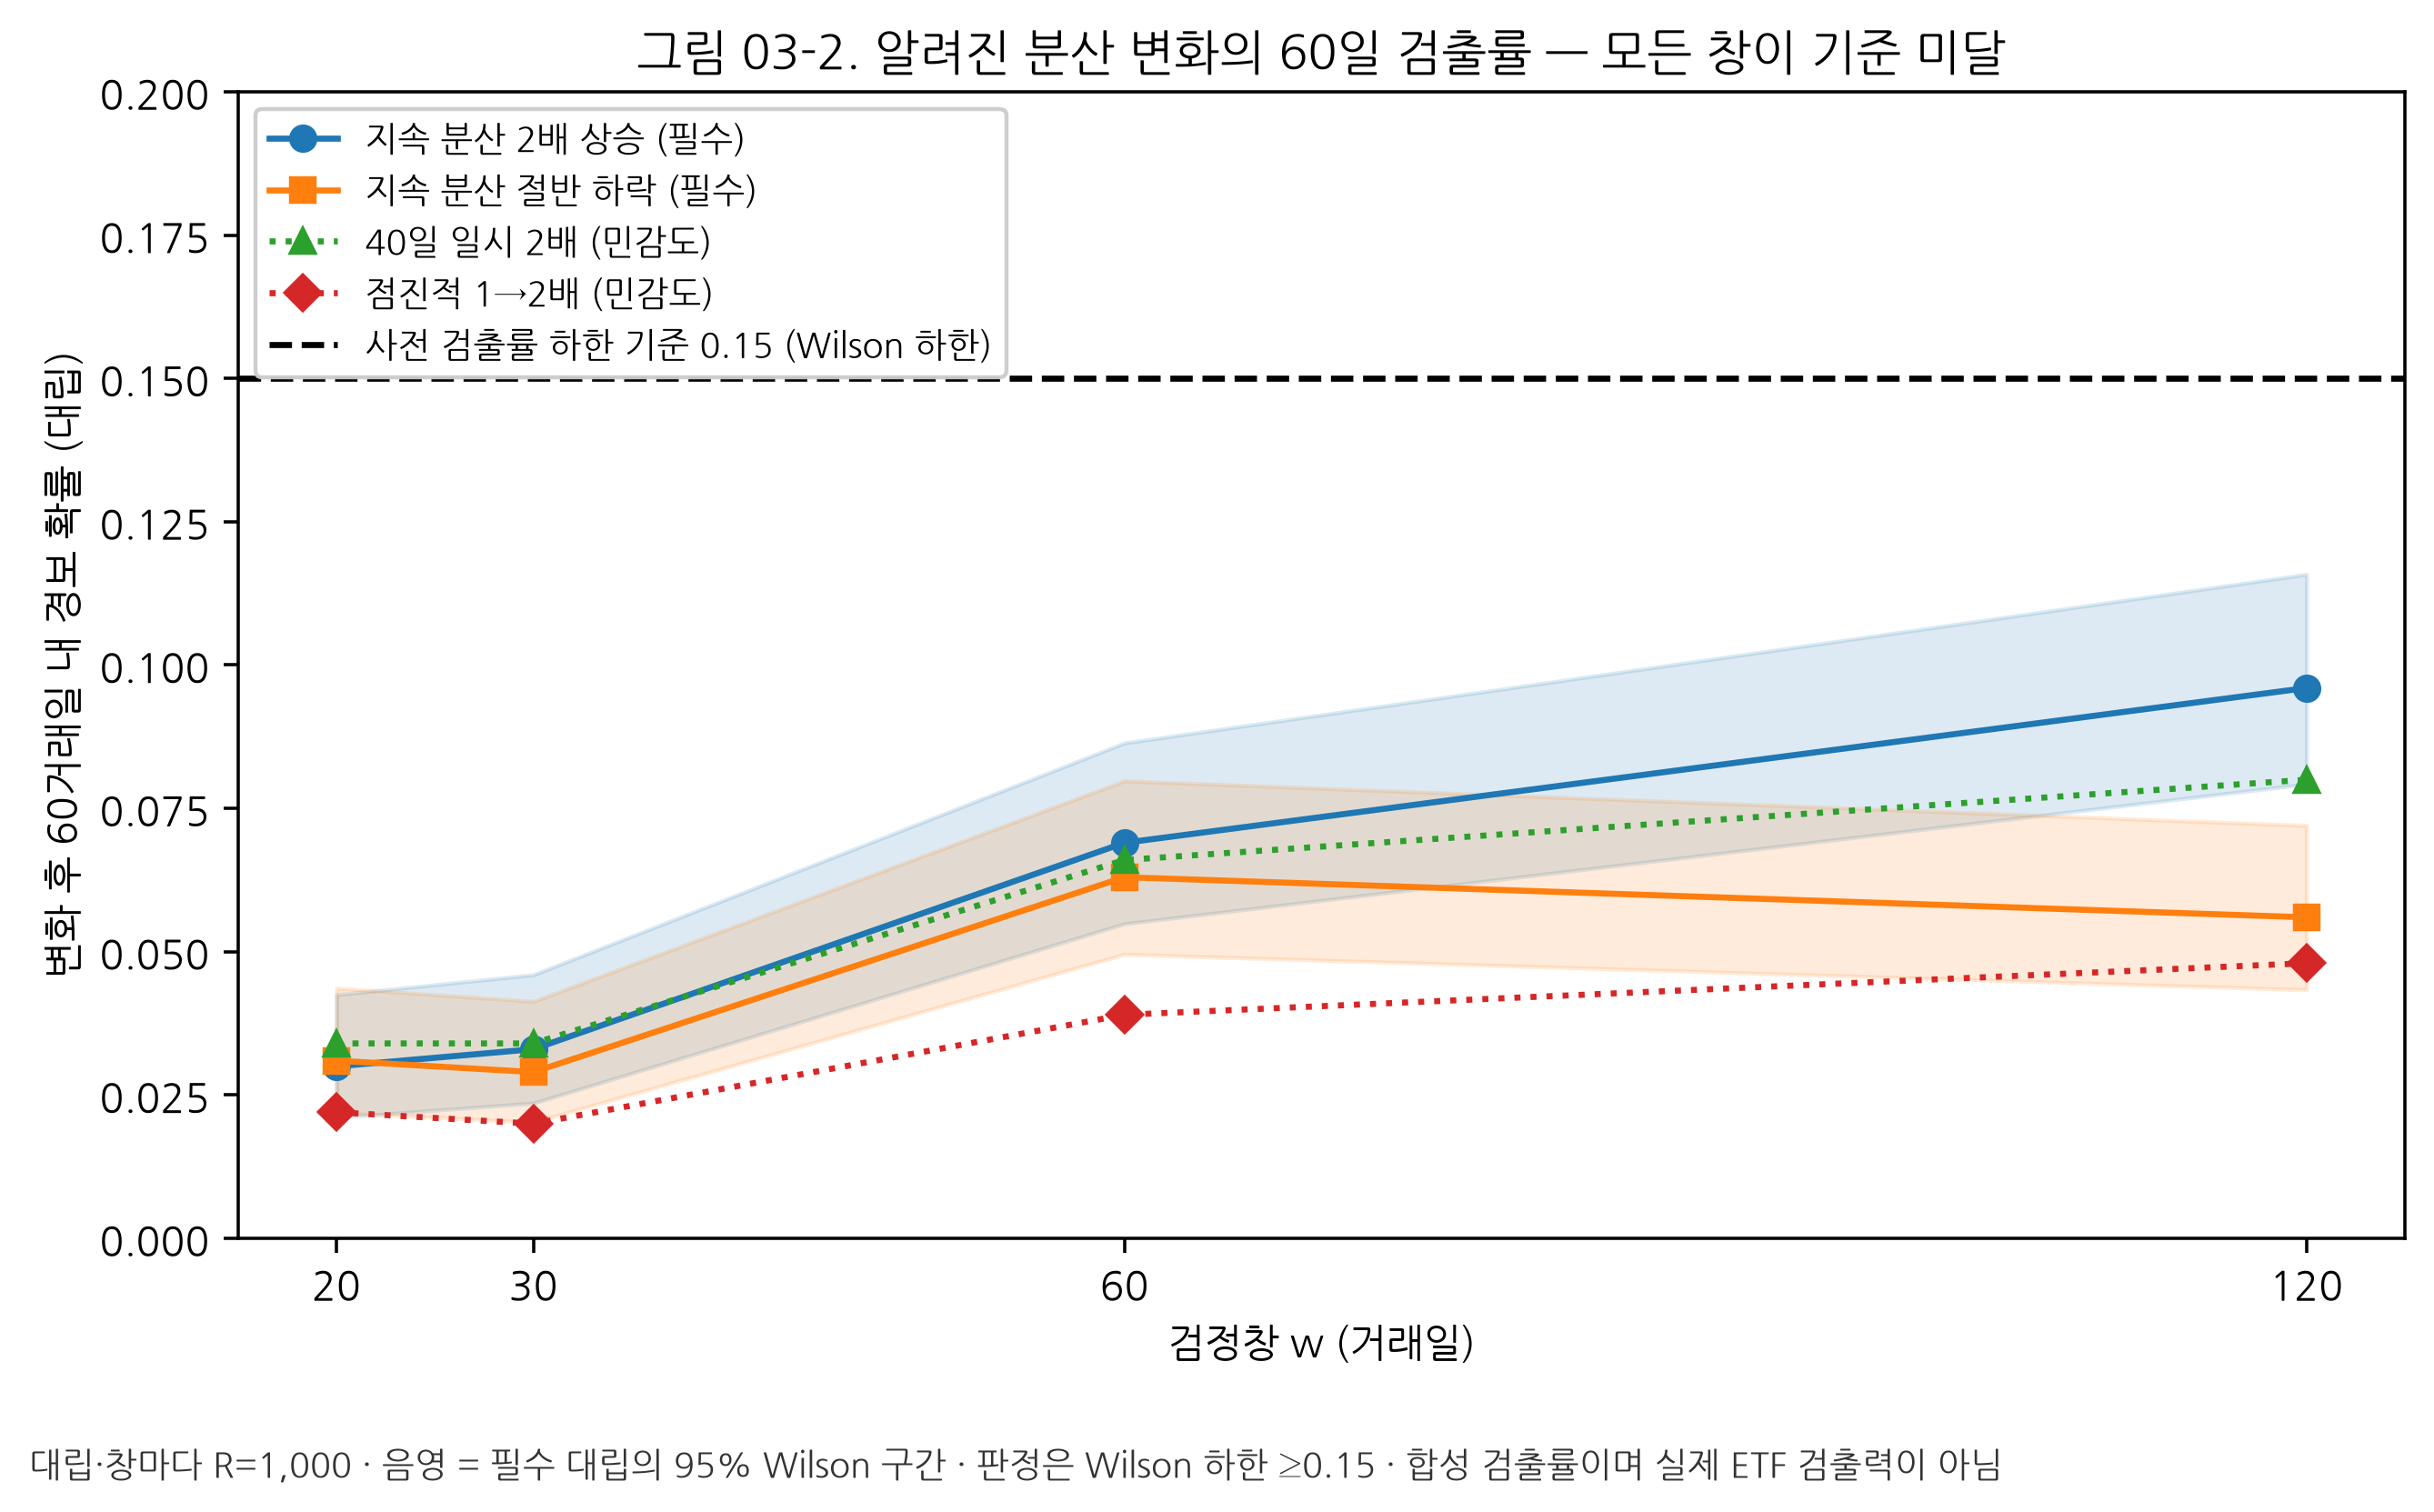

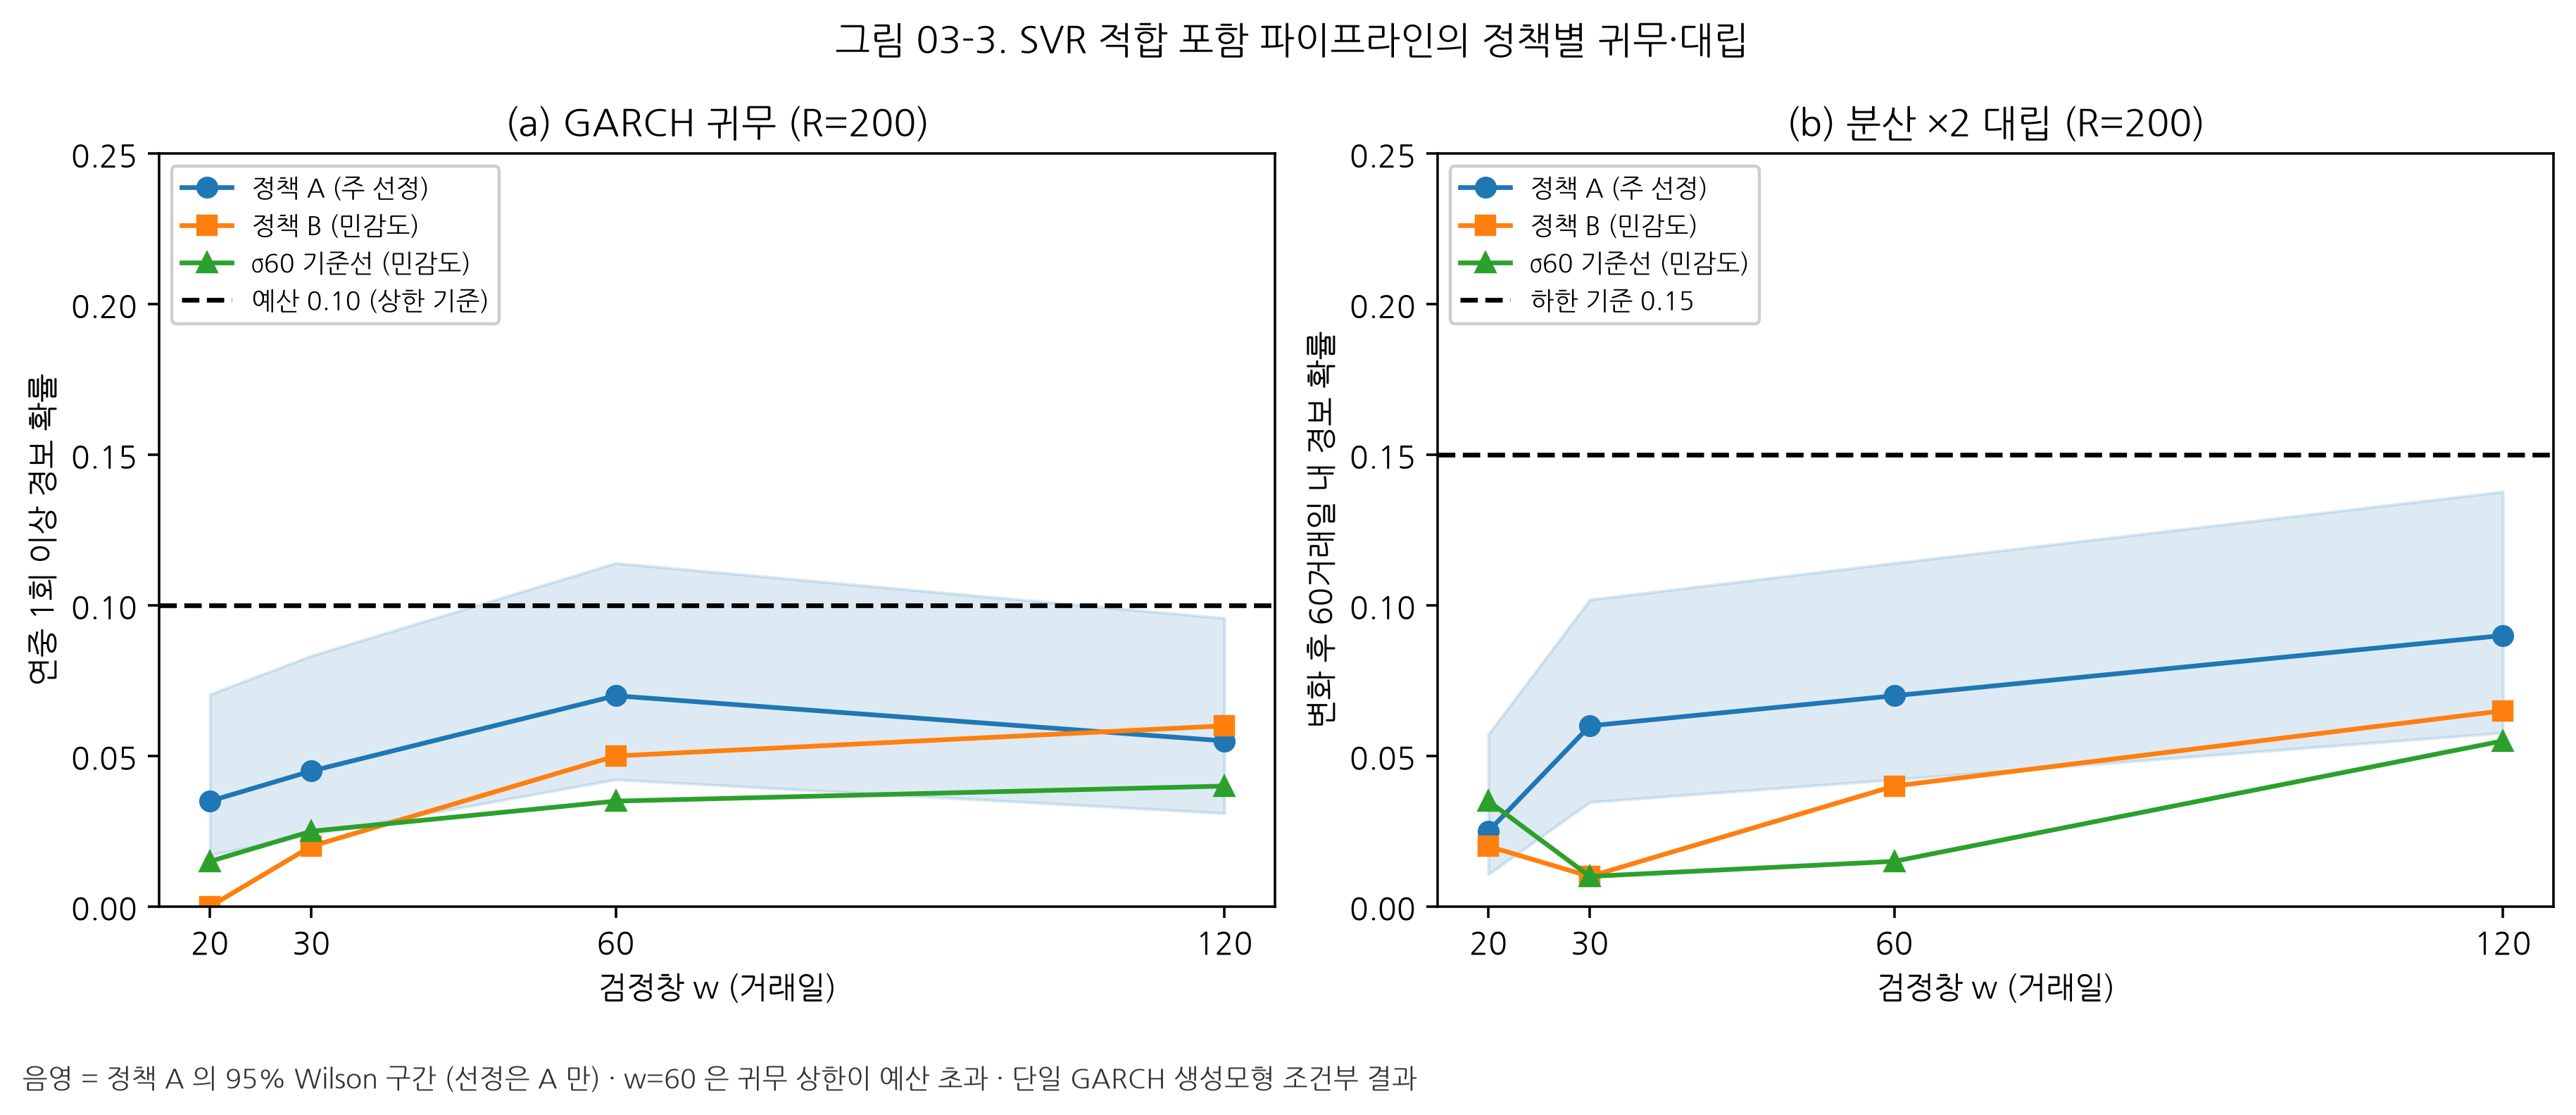

,그림,캡션,자료
0,fig03_01_귀무_연간경보,"세 귀무·245거래일 모의, 공통 126일(t≥119) 평가. 연간 경보는 점별 5...",detector_summary.csv
1,fig03_02_합성_검출률,"합성 GARCH 변화 4종, 변화 시점 k=122. 지속 상승·하락만 필수 조건이며...",detector_summary.csv
2,fig03_03_적합포함_귀무,모의마다 과거 490일로 T12 27-grid SVR 재적합 후 A/B/base 잔...,pipeline_summary.csv


In [6]:
# 검출기·적합 포함 실험의 핵심 숫자와 판정 근거를 한국어 그림(PNG 320dpi + SVG)으로 보존한다.
from r2h.window_study.figures import real_path_figure, synthetic_figures  # W1 그림 함수

FIG03 = BASE / "figures/03"  # 03 그림 폴더
INDEX03 = synthetic_figures(DET["detector_summary.csv"], PIPE["pipeline_summary.csv"], SELECTION, FIG03)  # 그림 03-1~03-3
for item in INDEX03.itertuples(index=False):  # 그림마다
    display(Image(filename=item.PNG))  # 본문에 표시
display(INDEX03[["그림", "캡션", "자료"]])  # 그림 번호·캡션·근거 표

### 그림 03-1 ~ 03-3 해석

**03-1 (검출기 귀무).** 세 귀무 모두 모든 창에서 Wilson 상한이 예산 0.10 아래에 있다.
- GARCH 군집이 임계값을 정하기 때문에 GARCH 에서 경보 확률이 약 0.04–0.06 이다.
- 정규·t5 귀무에서는 w ≥ 60 에서 경보가 거의 0 이다. 이는 임계값이 iid 귀무에 대해 매우 보수적이라는 뜻이다.

**03-2 (검출기 대립).** 판정을 막은 것은 이 그림이다.
- 지속 ×2 상승과 ×0.5 하락의 60일 검출률은 모든 창에서 기준 하한 0.15 에 크게 못 미친다.
- 창이 길수록 검출률이 다소 오른다. 그러나 60일 검출률(0.03–0.10)은 같은 창의 GARCH 귀무 연간 경보 확률(126일 전체, 0.04–0.06)과 같은 자릿수다.
- 같은 60일 구간만의 귀무 경보율은 계산하지 않았다. 그래서 변화로 인한 검출과 군집으로 인한 경보를 분리하지 못했다.

**03-3 (적합 포함).**
- 정책 A 의 귀무 경보 확률은 모든 창에서 점추정 0.10 미만이다. 그러나 w=60 은 200회 반복의 Wilson 상한이 예산을 넘는다.
- 대립 검출률 하한은 모든 창에서 0.15 미만이다.

## 3. 실제 대표 4종 — 경보는 관측 통계량과 임계값의 비교일 뿐이다

**재계산.** 아래 표는 T12 동결 일별 잔차에 원본 `rolling_cusum` 을 **다시 적용**한 값이다. 같은 함수를 같은 잔차에 다시 쓴 것이므로 독립 재구현은 아니다. PURE 구간의 재계산 경로가 T12 cache 의 T 와 허용오차 1e-8 안에서 같지 않으면 중단한다.

**두 임계값.** 섞지 않고 분리해서 보고한다.
- `t12_pointwise_iid_insample`: 원 연구의 점별 임계값이다.
- `pipeline_garch_annual_max`: 이 연구의 연중 최대 임계값이다.

**주의.** 전자는 그 귀무가 시장에 맞는다는 보장이 없고, 후자는 합성 GARCH 를 가정한 것이다. 경보일과 에피소드는 실제 변화의 정답이 아니다.

In [7]:
# 대표 4종 × 2020–2026 × A/B/base × 5 창의 평가 가능일과 경보 부담을 재계산한다.
from r2h.window_study.empirical import empirical_experiment  # 실측 재계산 함수

REAL03 = empirical_experiment(ROOT, SOURCE, CFG, CFG["representative_tickers"], PIPE["pipeline_thresholds.csv"], BASE / "results/03_real")  # 4종
VALID03 = REAL03["validity.csv"]  # ETF·연도·정책·창별 평가 가능일
ALARM03 = REAL03["alarm_metrics.csv"]  # 임계값 종류·표본 종류별 경보 지표
core03 = ALARM03.query("year >= 2021 and year <= 2025 and policy == 'A' and sample_type == 'common'")  # 핵심 연도·정책 A·공통일
summary03 = core03.groupby(["ticker", "w", "threshold_type"]).agg(ETF_연도=("year", "nunique"), 유효일=("n_valid_days", "sum"), 경보일=("alarm_days", "sum"), 에피소드=("episodes", "sum"), 연중경보연도=("any_alarm", "sum")).reset_index()  # 종목·창·임계값별 합계
display(summary03)  # 표 3
display(VALID03.groupby(["w", "status"]).size().rename("ETF·연도·정책 수").reset_index())  # 평가 가능 상태 분포
display(REAL03["daily_cache_qa.csv"])  # T12 cache 대비 최대 차이·cache 해시
assert VALID03.query("w == 252").n_pure_valid.eq(0).all()  # w=252 는 PURE 구조적 불가
assert REAL03["daily_cache_qa.csv"].max_abs_pure_T_diff_from_T12_cache.max() < 1e-8  # 재계산 경로 = T12 cache

,ticker,w,threshold_type,ETF_연도,유효일,경보일,에피소드,연중경보연도
0,069500,20,pipeline_garch_annual_max,5,630,0,0,0
1,069500,20,t12_pointwise_iid_insample,5,630,16,8,3
2,069500,30,pipeline_garch_annual_max,5,630,0,0,0
3,069500,30,t12_pointwise_iid_insample,5,630,3,2,2
4,069500,60,pipeline_garch_annual_max,5,630,3,2,2
5,069500,60,t12_pointwise_iid_insample,5,630,3,2,2
6,069500,120,pipeline_garch_annual_max,5,630,1,1,1
7,069500,120,t12_pointwise_iid_insample,5,630,3,1,1
8,102110,20,pipeline_garch_annual_max,5,630,0,0,0
9,102110,20,t12_pointwise_iid_insample,5,630,18,9,3


,w,status,ETF·연도·정책 수
0,20,EVALUABLE,84
1,30,EVALUABLE,84
2,60,EVALUABLE,84
3,120,EVALUABLE,84
4,252,NO_FULL_WINDOW,84


,ticker,daily_sha256,max_abs_pure_T_diff_from_T12_cache,n_daily_rows
0,069500,ebd0c99b887b871b67f2e6818f938ed518ea05666880eb...,9.195724e-10,29826
1,229200,4e74ee6fbbb843e2c8e977ad5132581af2e2a2b20dabd2...,1.088578e-09,29826
2,148070,5dcb8f4831a6c4fb439eaf52ac9de1bb609b665b22bf90...,1.059176e-09,29826
3,102110,b28a81a0a81fa9e31b8508571e08da936cf8b7b56413e2...,8.989987e-10,29826


### 표 3 읽는 법

**분모.** `유효일` 은 2021–2025 다섯 해의 공통 PURE 유효일 합이다. 연중경보연도 는 0–5 사이 값이다.

**두 임계값의 차이.** 연중 최대 보정 임계값은 점별 임계값보다 높다. 그래서 같은 잔차라도 경보가 훨씬 적다. 이 차이는 보정 단위(하루 대 1년)의 차이다. 어느 쪽이 '정확' 하다는 뜻이 아니다.

**w=252.** 모든 연도·정책에서 `NO_FULL_WINDOW` 다. 평가 불가이며, 경보 0 으로 세지 않는다.

**cache 대비 차이.** 표의 `max_abs_pure_T_diff_from_T12_cache` 는 PURE 유효일에서 재계산한 T 와 T12 cache T 의 최대 절대차다. 1e-9 수준이며, cache 가 `%.10g` 로 직렬화될 때 생긴 반올림에서 온 것이다.

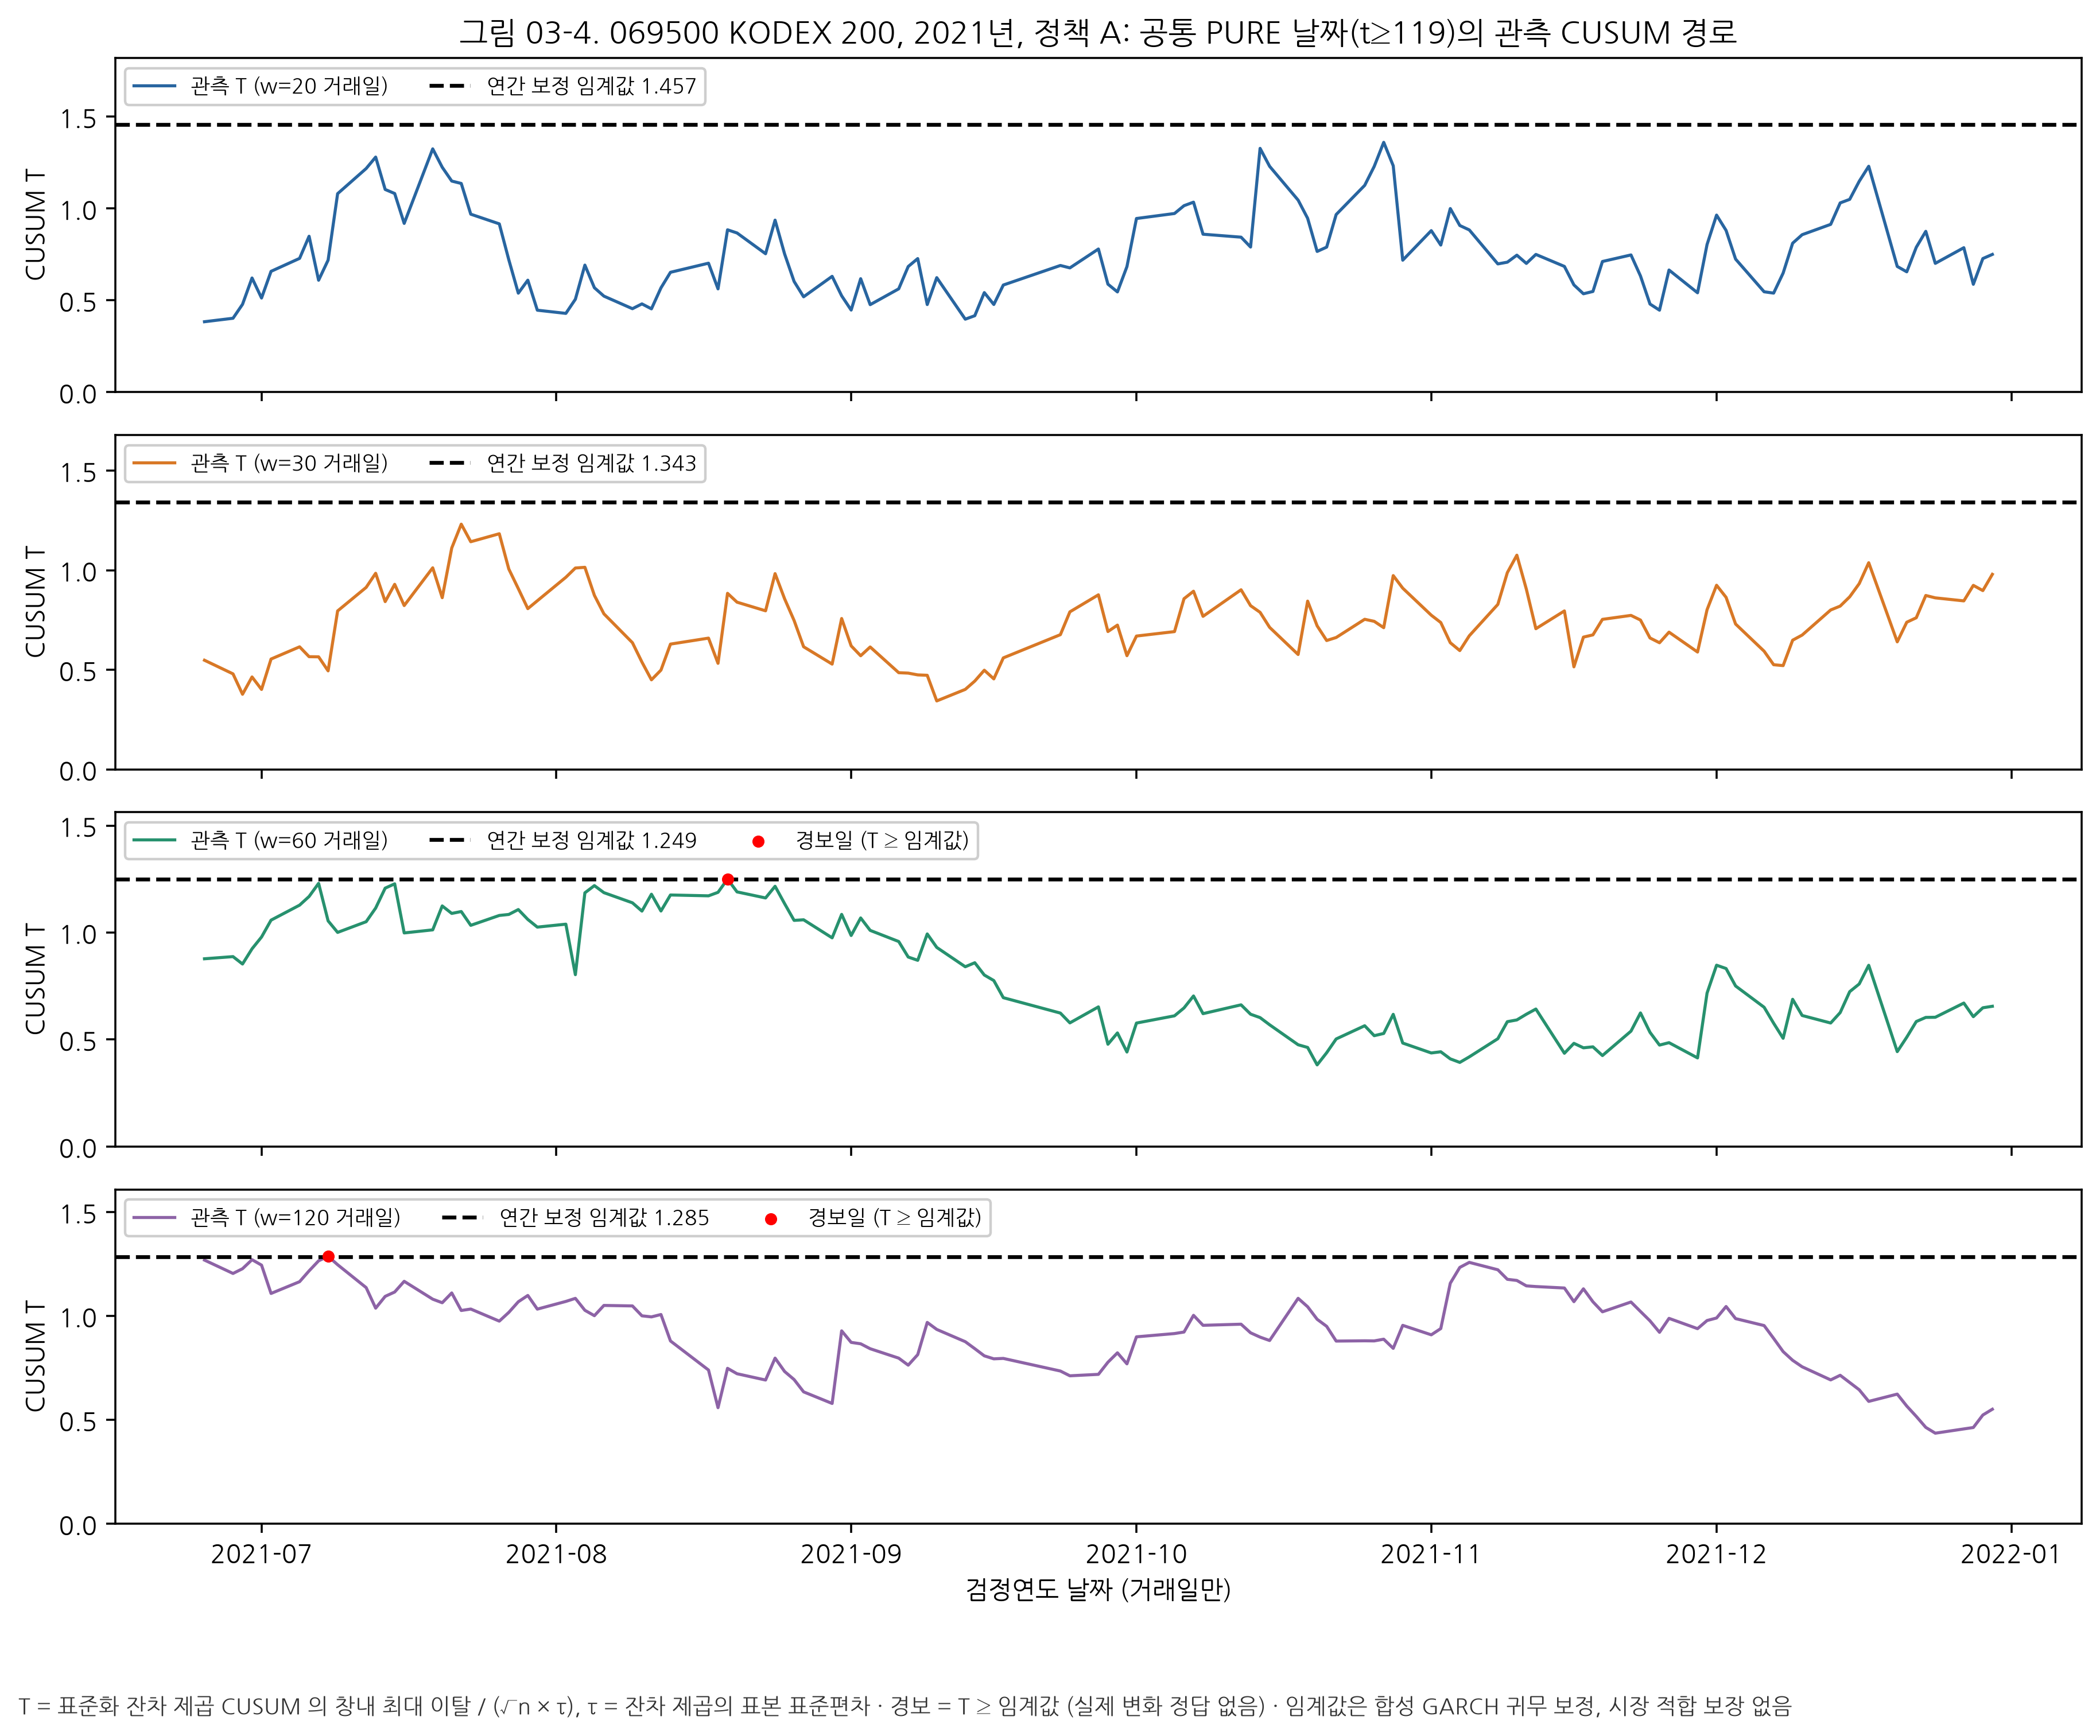

탐색적 에피소드 후보 수 (4종 · 2020–2026 · 모든 정책·창): 24
핵심 연도·정책 A 후보 수: 6


,ticker,year,policy,w,window_start,window_end,alarm_at,estimated_change_at,episode_last_alarm_at,threshold,T_at_alarm,boundary_mode,available_at,candidate_reason
0,069500,2020,A,60,2020-06-11,2020-09-03,2020-09-03,2020-06-25,2020-09-04,1.249443,1.289766,PURE_OOS_WINDOW_COMMON,2020-09-03 close,exploratory_first_episode_not_price_label
1,069500,2020,A,120,2020-01-13,2020-07-06,2020-07-06,2020-04-06,2020-09-14,1.284988,1.305228,PURE_OOS_WINDOW_COMMON,2020-07-06 close,exploratory_first_episode_not_price_label
2,069500,2020,A,120,2020-05-29,2020-11-19,2020-11-19,2020-06-25,2020-11-24,1.284988,1.286781,PURE_OOS_WINDOW_COMMON,2020-11-19 close,exploratory_first_episode_not_price_label
3,069500,2020,B,120,2020-03-06,2020-08-27,2020-08-27,2020-04-06,2020-08-28,2.188312,2.200207,PURE_OOS_WINDOW_COMMON,2020-08-27 close,exploratory_first_episode_not_price_label
4,069500,2020,base,120,2020-01-14,2020-07-07,2020-07-07,2020-03-25,2020-09-01,2.431592,2.432005,PURE_OOS_WINDOW_COMMON,2020-07-07 close,exploratory_first_episode_not_price_label
5,069500,2021,A,60,2021-05-27,2021-08-19,2021-08-19,2021-07-07,2021-08-19,1.249443,1.249871,PURE_OOS_WINDOW_COMMON,2021-08-19 close,exploratory_first_episode_not_price_label
6,069500,2021,A,120,2021-01-15,2021-07-08,2021-07-08,2021-03-11,2021-07-08,1.284988,1.287296,PURE_OOS_WINDOW_COMMON,2021-07-08 close,exploratory_first_episode_not_price_label
7,069500,2024,A,60,2024-05-10,2024-08-05,2024-08-05,2024-08-01,2024-08-06,1.249443,1.301309,PURE_OOS_WINDOW_COMMON,2024-08-05 close,exploratory_first_episode_not_price_label
8,229200,2020,base,20,2020-07-23,2020-08-20,2020-08-20,2020-08-11,2020-08-20,1.669970,1.670210,PURE_OOS_WINDOW_COMMON,2020-08-20 close,exploratory_first_episode_not_price_label
9,229200,2020,base,30,2020-07-09,2020-08-20,2020-08-20,2020-08-11,2020-08-25,1.797171,1.830345,PURE_OOS_WINDOW_COMMON,2020-08-20 close,exploratory_first_episode_not_price_label


In [8]:
# 같은 ETF·연도·정책에서 네 창의 실제 T 경로를 비교한다. 경보와 사후 변화위치를 혼동하지 않는다.
INDEX03 = pd.concat([INDEX03, real_path_figure(SOURCE, CFG["base_t12_run_id"], "069500", 2021, "A", PIPE["pipeline_thresholds.csv"], FIG03)], ignore_index=True)  # 그림 03-4
display(Image(filename=INDEX03.iloc[-1].PNG))  # 본문에 표시
candidate03 = REAL03["cnn_candidate_intervals.csv"]  # 연중 최대 임계값·공통일 기준의 첫 경보 에피소드
print("탐색적 에피소드 후보 수 (4종 · 2020–2026 · 모든 정책·창):", len(candidate03))  # 후보 행 수
print("핵심 연도·정책 A 후보 수:", int(candidate03.query("policy == 'A' and year >= 2021 and year <= 2025").shape[0]))  # 주 분석 범위
display(candidate03.head(12))  # 후보 메타데이터 예시

### 그림 03-4 와 선정 실패의 의미

**그림 03-4.** 실선은 같은 069500·2021·정책 A 잔차에서 나온 창별 **실측 T** 이고, 점선은 같은 정책·창의 **합성 연간 임계값** 이다.
- 실선이 점선을 넘은 첫 거래일의 마감 뒤에야 경보를 알 수 있다.
- `estimated_change_at` 은 경보 창 안의 사후 최대 이탈 위치다. 독립 가격 라벨이나 미래 예측 시각이 아니다.
- 표 3 의 네 종목 경보 수는 독립 시행처럼 더할 수 없다. 동일 노출(069500·102110), 겹치는 창, 공통 시장 요인이 있기 때문이다.

**적격 0 의 의미.**
- W1 에서 적격 후보가 0 이면, 그것 자체가 결론이다.
- 귀무 크기는 맞췄다. 그러나 이 통계량과 공통 평가일, 60거래일 지평에서는 알려진 2배 분산 변화도 기준 수준(하한 0.15)만큼 검출하지 못했다.
- 어떤 창이 실제 ETF 에서 경보가 적다고 해서 실제 변화를 덜 놓친다는 뜻은 아니다.

**대안적 설명.** 낮은 검출력에는 세 가지 설명이 가능하다. 지금 자료로는 이 셋을 분리하지 않았다.
1. `τ̂` 정규화가 창 안 분산 변화를 함께 흡수한다 (T12 감사 Q7).
2. 공통 평가일이 `t ≥ 119` 로 늦게 시작한다. 그래서 짧은 창의 이점이 줄어든다.
3. GARCH 귀무가 임계값을 높인다.

In [9]:
# 04 가 정확히 이 실행의 설정·보정 임계값·판정만 읽도록 파일 지문을 남긴다.
INDEX03.to_csv(BASE / "figures/03/figure_index.csv", index=False)  # 그림 색인·해시
source_files = [BASE / "results/03_synthetic/detector/detector_summary.csv", BASE / "results/03_synthetic/detector/detector_thresholds.csv", BASE / "results/03_synthetic/pipeline/pipeline_summary.csv", BASE / "results/03_synthetic/pipeline/pipeline_thresholds.csv", BASE / "최적창_판정과_보류사유.csv", BASE / "results/03_real/validity.csv", BASE / "results/03_real/alarm_metrics.csv"]  # 인계 대상 7개
FILE_SHA = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}  # 파일별 SHA256
TRANSFER = {"study_id": CFG["study_id"], "config_sha256": CONFIG_SHA, "base_commit": CFG["base_t12_commit"], "base_run_id": CFG["base_t12_run_id"], "files_sha256": FILE_SHA, "eligible_windows": SELECTION.loc[SELECTION.eligible, "w"].astype(int).tolist(), "pareto_windows": SELECTION.loc[SELECTION.pareto, "w"].astype(int).tolist(), "execution_seconds": round(time.time() - START03, 2), "environment": ACTUAL_ENV, "mode": "FULL_EXECUTED"}  # 인계 계약
(BASE / "03_to_04_transfer.json").write_text(json.dumps(TRANSFER, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")  # 04 입력
print("03 full 완료:", TRANSFER["execution_seconds"], "초; 인계 파일 지문", len(FILE_SHA), "개")  # 실행 기록
display(pd.DataFrame([{"파일": k, "SHA256": v} for k, v in FILE_SHA.items()]))  # 지문 표

03 full 완료: 191.53 초; 인계 파일 지문 7 개


,파일,SHA256
0,research/window_study_w1/results/03_synthetic/...,6b7dcd889ea1bbd6b26bbdb18c6a39b0bf0341a8b102df...
1,research/window_study_w1/results/03_synthetic/...,d3b9aa279d674661a773970ed83ffb60d5840da6aefe12...
2,research/window_study_w1/results/03_synthetic/...,463ed41edd404d40551d10241064b8a3cec1a4f04b6691...
3,research/window_study_w1/results/03_synthetic/...,3ddfe1521e1ded12060ef6a1e6f4a925b1af251f8b4cee...
4,research/window_study_w1/최적창_판정과_보류사유.csv,9ff9af16c1f105847397f1a39fff3bbae973632648dee9...
5,research/window_study_w1/results/03_real/valid...,1c99826636df83a87993f540b1c9816599d385fef1a702...
6,research/window_study_w1/results/03_real/alarm...,fcb1c87f1cde85bf18f9685571101eef03f02684fa86eb...


## 4. 결론과 주장 범위

**계산으로 확인한 사실.**
- 네 창(20/30/60/120 거래일) 모두 W1 사전 조건을 통과하지 못했다. 적격 후보는 0/4 이며, 위 판정표에 실패 사유가 있다.
- 4종의 창별 실측 T, 경보일, 평가 가능일은 T12 cache 와 일치하는 재계산이다.

**가정 아래에서만 가능한 해석.**
- 합성 GARCH·t5·정규 귀무가 시장을 대표한다면, 연간 보정 임계값은 귀무 경보를 0.10 아래로 막는다.
- 같은 조건에서 60일 안에 2배 분산 변화를 잡을 확률은 0.1 정도에 그친다.

**현재 자료로는 판단할 수 없는 주장.**
- ETF 경보가 시장의 실제 구조변화라는 주장.
- 어떤 창이 실제로 '더 좋은' 탐지기라는 주장.
- 가격 급등 탐지 성능.

**다음 연구의 전제.** 실제 급등 시작을 연구하려면 독립 가격 라벨, 사전에 정한 허용 지연·오경보 비용, 아직 관찰하지 않은 기간·자산에서의 블라인드 평가가 필요하다.

**비교 불가.** T11 70:30 과 T12 연간은 검정 단위와 학습 시점이 달라, 기각 건수로 비교할 수 없다. 원논문 충실 재현과 온라인 탐지는 이 연구 밖에 있다.

In [10]:
# 본문 결론(적격 0/4)이 이 실행의 판정표와 같은지 확인한다. 다르면 본문을 고쳐야 한다 (규칙은 고치지 않는다).
assert int(SELECTION.eligible.sum()) == 0 and not SELECTION.pareto.any(), "본문 결론과 실행 판정이 다릅니다"  # 서술-결과 정합성
print("서술-결과 정합성 확인: 적격 0/4, 최적창 없음")  # 확인 기록

서술-결과 정합성 확인: 적격 0/4, 최적창 없음
